# Import modules:

In [159]:
import numpy as np
import matplotlib.pyplot as plt

In [163]:
class Graph:
    def __init__(self):
        self.fig, self.ax = plt.subplots()

        # x = 0 and y = 0 axes
        self.ax.spines['left'].set_position('zero')
        self.ax.spines['bottom'].set_position('zero')
        self.ax.spines['top'].set_color('none')
        self.ax.spines['right'].set_color('none')

        # Arrowheads
        self.ax.plot(1, 0, '>k',
                     transform=self.ax.get_yaxis_transform(),
                     clip_on=False)
        self.ax.plot(0, 1, '^k',
                     transform=self.ax.get_xaxis_transform(),
                     clip_on=False)

        #self.ax.set_xlim(-5, 5)
        #self.ax.set_ylim(-5, 5)

    def show(self):
        plt.show()

# Define Newton Rafson function (it checked if the derivative is zero):

In [164]:
def newton_method(f, df, x0, tolerance=1e-6, max_iterations=100):
    """
    Newton's method for solving f(x) = 0.

    Parameters:
        f              : function f(x)
        df             : derivative f'(x)
        x0             : initial guess
        tolerance      : stopping tolerance
        max_iterations : maximum number of iterations

    Returns:
        Approximate root
    """

    xn = x0

    for it in np.arange(max_iterations):
        # Avoid division by zero
        if df(xn) == 0:
            print("Derivative is zero. Newton's method cannot continue.")
            return None

        # Newton's method formula
        xn1 = xn - f(xn) / df(xn)

        # Check convergence
        if abs(xn1 - xn) < tolerance:
            print(f"Converged after {it + 1} iterations.")
            return xn1

        xn = xn1

    print("Maximum number of iterations reached.")
    return xn

# Define a function with two zero:

In [165]:
def f1(x):
    return x**2 - 4

def df1(x):
    return 2*x

root = newton_method(f1, df1, x0=4)
print("Root:", root)

root = newton_method(f1, df1, x0=300)
print("Root:", root)

root = newton_method(f1, df1, x0=0)
print("Root:", root)

root = newton_method(f1, df1, x0=-1)
print("Root:", root)

root = newton_method(f1, df1, x0=-300)
print("Root:", root)

Converged after 5 iterations.
Root: 2.000000000000002
Converged after 12 iterations.
Root: 2.0
Derivative is zero. Newton's method cannot continue.
Root: None
Converged after 5 iterations.
Root: -2.000000000000002
Converged after 12 iterations.
Root: -2.0


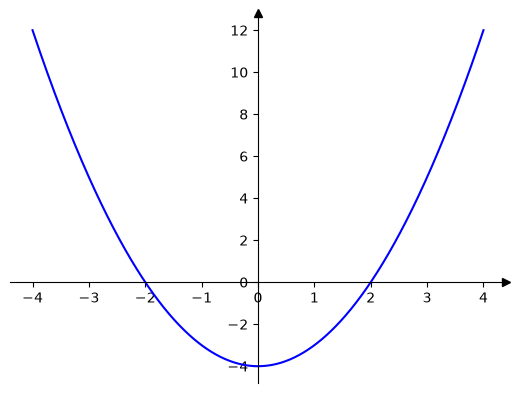

In [166]:
xx=np.arange(801)/100-4.
yy=f1(xx)

graph1 = Graph()
graph1.ax.plot(xx,yy,color='blue')

# Define a trigo function:

In [167]:
def f2(x):
    return np.cos(x) - x

def df2(x):
    return -np.sin(x) - 1

root = newton_method(f2, df2, x0=2)
print("Root:", root)

root = newton_method(f2, df2, x0=200)
print("Root:", root)

Converged after 4 iterations.
Root: 0.7390851332151607
Converged after 99 iterations.
Root: 0.7390851332151611


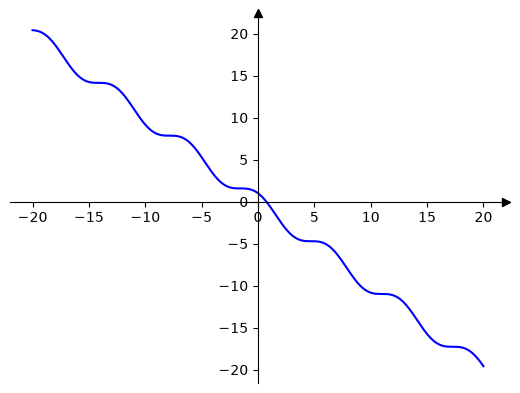

In [168]:
xx=np.arange(4001)/100-20.
yy=f2(xx)

graph2 = Graph()
graph2.ax.plot(xx,yy,color='blue')

# Oscillating function (Problem 1)

In [169]:
def f3(x):
    return x**3 - 2*x + 2

def df3(x):
    return 3*x**2 - 2

root = newton_method(f3, df3, x0=0.)

print("Root:", root)

Maximum number of iterations reached.
Root: 0.0


In [173]:
nt3 = 100
xn3 = np.empty(nt3+1)
xn3[0]=0.

for it in np.arange(nt3):
    xn3[it+1] = xn3[it] - f3(xn3[it]) / df3(xn3[it])

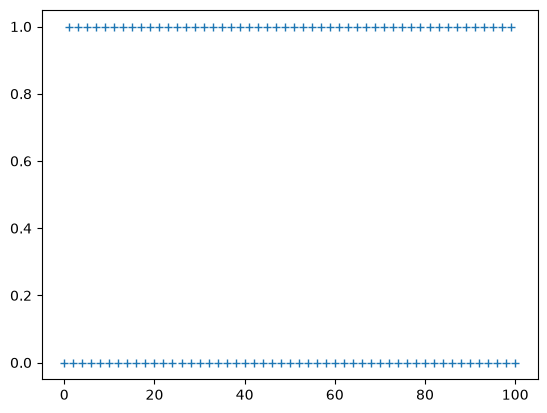

In [174]:
plt.plot(xn3,'+')

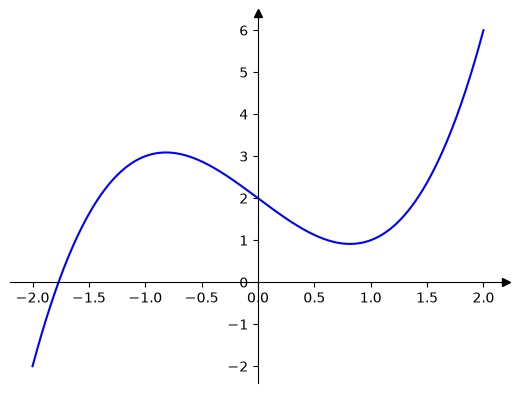

In [175]:
xx=np.arange(401)/100-2.
yy=f3(xx)

graph3 = Graph()
graph3.ax.plot(xx,yy,color='blue')

# The friction law (Problem 2)

In [176]:
def f_fric(x,sigma_n=100,a=0.01,Vstar=10**(-6),mustar=0.6,tau_app=40):
    return sigma_n * (mustar + a * np.log(x / Vstar)) - tau_app

def df_fric(x,sigma_n=100,a=0.01):
    return sigma_n * a / x

V0=10**(-6)

root = newton_method(f_fric, df_fric, x0=V0)

print(f" f(V0) = {f_fric(V0)}  and  df(V0) = {df_fric(V0)}")
print(f" V1 = {V0 - f_fric(V0) / df_fric(V0)}")

Maximum number of iterations reached.
 f(V0) = 20.0  and  df(V0) = 1000000.0
 V1 = -1.9e-05


/tmp/ipykernel_611965/2875960724.py:2: RuntimeWarning: invalid value encountered in log
  return sigma_n * (mustar + a * np.log(x / Vstar)) - tau_app


In [177]:
def g_fric(x,sigma_n=100,a=0.01,mustar=0.6,tau_app=40):
    return sigma_n * (mustar + a * x) - tau_app

def dg_fric(x,sigma_n=100,a=0.01):
    return sigma_n * a

Vstar=10**(-6)

root = newton_method(g_fric, dg_fric, x0=0.)
print("Root:", Vstar * np.exp(root))

Converged after 2 iterations.
Root: 2.0611536224385577e-15


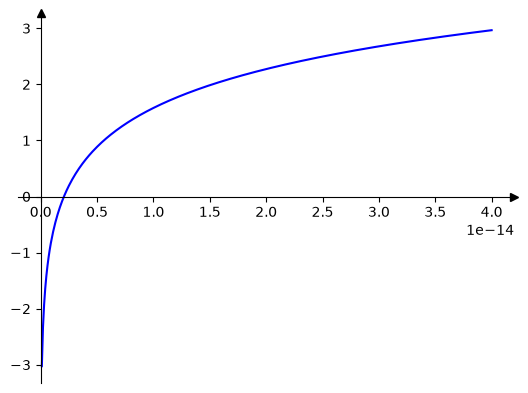

In [178]:
xx=np.arange(400)/10**(16)+1/10**(16)
yy=f_fric(xx)

graph_fric = Graph()
graph_fric.ax.plot(xx,yy,color='blue')

# Smooth function (Problem 3)

In [179]:
def f_smooth(x):
    return np.arctan(x)

def df_smooth(x):
    return 1. / (1. + x**2)

root = newton_method(f_smooth, df_smooth, x0=2.)
print("Root:", root)

root = newton_method(f_smooth, df_smooth, x0=1.4)
print("Root:", root)

root = newton_method(f_smooth, df_smooth, x0=1.3)
print("Root:", root)

root = newton_method(f_smooth, df_smooth, x0=1.)
print("Root:", root)

root = newton_method(f_smooth, df_smooth, x0=0.5)
print("Root:", root)

Derivative is zero. Newton's method cannot continue.
Root: None
Derivative is zero. Newton's method cannot continue.
Root: None
Converged after 7 iterations.
Root: 0.0
Converged after 5 iterations.
Root: 0.0
Converged after 4 iterations.
Root: 0.0


/tmp/ipykernel_611965/1408656632.py:5: RuntimeWarning: overflow encountered in scalar power
  return 1. / (1. + x**2)


In [180]:
print(f" f(x0) = {f_smooth(x0)}  and  df(x0) = {df_smooth(x0)}")
print(f" x1 = {x0 - f_smooth(x0) / df_smooth(x0)}")

 f(x0) = 1.1071487177940904  and  df(x0) = 0.2
 x1 = -3.535743588970452


In [181]:
nt_smooth = 8
xn_smooth = np.empty(nt_smooth+1)
xn_smooth[0]=2.

for it in np.arange(nt_smooth):
    xn_smooth[it+1] = xn_smooth[it] - f_smooth(xn_smooth[it]) / df_smooth(xn_smooth[it])

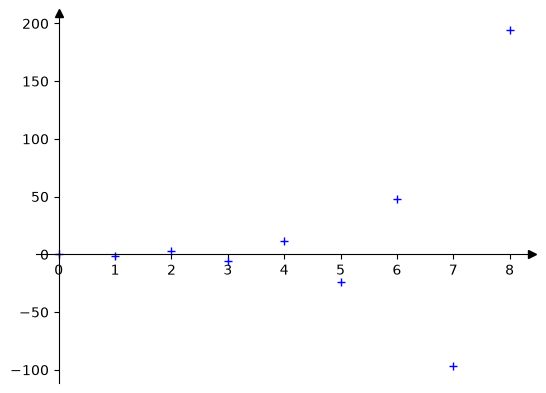

In [182]:
graph_growth = Graph()
graph_growth.ax.plot(np.sign(xn_smooth) * np.log(np.abs(xn_smooth)),"+",color='blue')

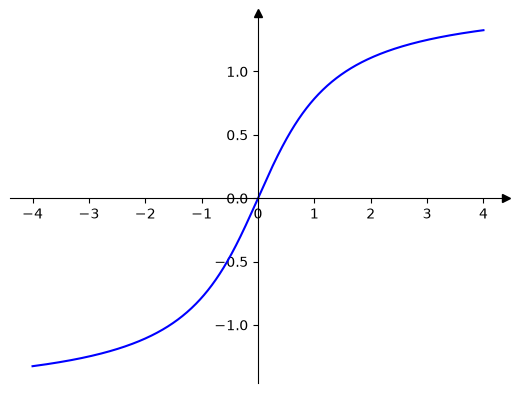

In [183]:
xx=np.arange(801)/100-4.
yy=f_smooth(xx)

graph_smooth = Graph()
graph_smooth.ax.plot(xx,yy,color='blue')